# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MbaliThusi/Mbali-Flyrank-intern-rep./blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

In [9]:
import pandas as pd, numpy as np, os
from google.colab import files
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score

uploaded = files.upload()
df = pd.read_csv(list(uploaded.keys())[0])
print(df.shape)

Saving content_refresh_anonymized.csv to content_refresh_anonymized (1).csv
(30000, 44)


## 1. Question

*The research question and the decision it supports.*

In [10]:
base = df[df["clicks_prev_30d"] > 0].copy()
y = (base["clicks_last_30d"] < base["clicks_prev_30d"]).astype(int)
groups = base["client_id"]
print("label = clicks_last_30d < clicks_prev_30d")
print("decline rate:", round(float(y.mean()), 3), "| this is the random-guess precision")

label = clicks_last_30d < clicks_prev_30d
decline rate: 0.579 | this is the random-guess precision


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

In [11]:
print("rows:", len(df), "| columns:", df.shape[1])
print("distinct content_id:", df["content_id"].nunique(), "| duplicate keys:", int(df.duplicated(["content_id"]).sum()))
print("clients:", df["client_id"].nunique())
print("content age range (days):", df["content_age_days"].min(), "->", df["content_age_days"].max())
print("windows: prev_30d, last_30d (label), 90d = both plus 30 earlier days")
print("excluded rows (no prior clicks, decline undefined):", int((df["clicks_prev_30d"] <= 0).sum()))

excluded = {
    "*_last_30d": "the outcome window",
    "*_90d, days_with_*, ctr, avg_position, engagement_rate, scroll_rate, ai_traffic_pct": "overlap the outcome window",
    "trend_direction, trend_pct, *_tier": "derived from the label or bucketed 90d metrics",
    "client_id, content_id": "identifiers, used only for grouping",
}
for k, v in excluded.items():
    print(f"- {k}: {v}")

rows: 30000 | columns: 44
distinct content_id: 30000 | duplicate keys: 0
clients: 32
content age range (days): 90 -> 564
windows: prev_30d, last_30d (label), 90d = both plus 30 earlier days
excluded rows (no prior clicks, decline undefined): 18241
- *_last_30d: the outcome window
- *_90d, days_with_*, ctr, avg_position, engagement_rate, scroll_rate, ai_traffic_pct: overlap the outcome window
- trend_direction, trend_pct, *_tier: derived from the label or bucketed 90d metrics
- client_id, content_id: identifiers, used only for grouping


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

In [12]:
cat_cols = ["content_type", "main_intent", "competition_level", "provider_used", "model_used"]
num_cols = ["search_volume", "competition", "cpc", "word_count", "char_count",
            "content_age_days", "days_since_last_update",
            "impressions_prev_30d", "clicks_prev_30d", "sessions_prev_30d"]
X = base[num_cols + cat_cols].copy()
X["chars_per_word"] = base["char_count"] / base["word_count"].replace(0, np.nan)
X["prev_ctr"] = base["clicks_prev_30d"] / base["impressions_prev_30d"].replace(0, np.nan)
X["log_clicks_prev"] = np.log1p(base["clicks_prev_30d"])
X["log_impr_prev"] = np.log1p(base["impressions_prev_30d"])
X = X.replace([np.inf, -np.inf], np.nan)
for c in list(X.select_dtypes("number").columns):
    if X[c].isna().any():
        X[c + "_was_missing"] = X[c].isna().astype(int)
        X[c] = X[c].fillna(X[c].median())
X[cat_cols] = X[cat_cols].fillna("unknown")
X = pd.get_dummies(X, columns=cat_cols, drop_first=True).astype(float)
print("features:", X.shape[1])

# Leakage checks
rows = []
for c in X.columns:
    try:
        a = roc_auc_score(y, X[c]); rows.append((c, max(a, 1 - a)))
    except Exception:
        pass
single = pd.DataFrame(rows, columns=["feature", "single_auc"]).sort_values("single_auc", ascending=False)
print("\nstrongest single features (suspect if > 0.8):\n", single.head(5).round(3).to_string(index=False))

Xleak = X.copy(); Xleak["LEAK_last_30d"] = base["clicks_last_30d"].values
tr, te = next(GroupKFold(5).split(X, y, groups))
for name, XX in [("final features", X), ("with deliberate leak", Xleak)]:
    m = HistGradientBoostingClassifier(max_depth=4, max_iter=100, random_state=0).fit(XX.iloc[tr], y.iloc[tr])
    print(f"{name}: AUC = {roc_auc_score(y.iloc[te], m.predict_proba(XX.iloc[te])[:, 1]):.3f}")

used = num_cols + cat_cols
banned = ["_90d", "last_30d", "tier", "trend_", "engagement", "scroll_rate", "ai_traffic", "days_with_"]
print("banned patterns in inputs:", [c for c in used if any(b in c for b in banned)] or "none")

features: 35

strongest single features (suspect if > 0.8):
                           feature  single_auc
                         prev_ctr       0.673
                  clicks_prev_30d       0.561
                  log_clicks_prev       0.561
model_used_gemini-3-flash-preview       0.555
                    log_impr_prev       0.555
final features: AUC = 0.636
with deliberate leak: AUC = 0.999
banned patterns in inputs: none


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

In [5]:
def p_at_10(yt, s):
    k = int(len(s) * 0.10)
    return np.asarray(yt)[np.argsort(-np.asarray(s))[:k]].mean()

def run(splitter, **kw):
    names = ["baseline: staleness rule", "logistic", "boosting"]
    rows = []
    for tr, te in splitter.split(X, y, **kw):
        scores = {"baseline: staleness rule": base["days_since_last_update"].iloc[te].fillna(0).values}
        lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X.iloc[tr], y.iloc[tr])
        gb = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=200, random_state=0).fit(X.iloc[tr], y.iloc[tr])
        scores["logistic"] = lr.predict_proba(X.iloc[te])[:, 1]
        scores["boosting"] = gb.predict_proba(X.iloc[te])[:, 1]
        for n in names:
            yt = y.iloc[te]
            rows.append([n, roc_auc_score(yt, scores[n]), average_precision_score(yt, scores[n]), p_at_10(yt, scores[n])])
    return pd.DataFrame(rows, columns=["model", "AUC", "AvgPrec", "Prec@top10%"])

honest = run(GroupKFold(5), groups=groups)
random_ = run(StratifiedKFold(5, shuffle=True, random_state=0))

table = honest.groupby("model").agg(["mean", "std"]).round(3)
print("HONEST SPLIT (grouped by client):\n", table, "\n")
print("random guess: AUC 0.5, precision", round(float(y.mean()), 3))

cmp_ = pd.DataFrame({
    "random split AUC": random_.groupby("model")["AUC"].mean(),
    "grouped split AUC": honest.groupby("model")["AUC"].mean(),
}).round(3)
cmp_["drop"] = (cmp_["random split AUC"] - cmp_["grouped split AUC"]).round(3)
print("\nBEFORE / AFTER:\n", cmp_)

HONEST SPLIT (grouped by client):
                             AUC        AvgPrec        Prec@top10%       
                           mean    std    mean    std        mean    std
model                                                                   
baseline: staleness rule  0.517  0.022   0.593  0.078       0.605  0.112
boosting                  0.646  0.008   0.693  0.068       0.756  0.071
logistic                  0.653  0.020   0.702  0.071       0.774  0.087 

random guess: AUC 0.5, precision 0.579

BEFORE / AFTER:
                           random split AUC  grouped split AUC   drop
model                                                               
baseline: staleness rule             0.480              0.517 -0.037
boosting                             0.698              0.646  0.052
logistic                             0.690              0.653  0.037


## 5. Limitations

*What this work cannot claim.*

In [6]:
print("snapshot rows:", len(df), "| clients:", df["client_id"].nunique())
print("youngest content (days):", df["content_age_days"].min(), "(nothing newer than 90 days)")

low = base["clicks_prev_30d"] < 10
print("rows with <10 prior clicks:", round(float(low.mean()), 3))

# Is the signal weaker on low-traffic rows? (grouped CV, boosting)
oof = np.zeros(len(X))
for tr, te in GroupKFold(5).split(X, y, groups):
    m = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=200, random_state=0).fit(X.iloc[tr], y.iloc[tr])
    oof[te] = m.predict_proba(X.iloc[te])[:, 1]
for name, mask in [("<10 prior clicks", low.values), (">=10 prior clicks", ~low.values)]:
    print(f"AUC on {name}: {roc_auc_score(y[mask], oof[mask]):.3f}  (n={int(mask.sum())})")

snapshot rows: 30000 | clients: 32
youngest content (days): 90 (nothing newer than 90 days)
rows with <10 prior clicks: 0.732
AUC on <10 prior clicks: 0.654  (n=8608)
AUC on >=10 prior clicks: 0.547  (n=3151)


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

In [7]:
q = base[["client_id", "content_id", "clicks_prev_30d", "impressions_prev_30d", "days_since_last_update"]].copy()
q["decline_risk"] = oof                      # out-of-fold, so each row was scored by a model that never saw its client
q["prev_ctr"] = X["prev_ctr"].values

hi_ctr = q["prev_ctr"] >= q["prev_ctr"].quantile(.75)
stale = q["days_since_last_update"] > 180
big = q["clicks_prev_30d"] >= 50

q["reason_code"] = np.select(
    [hi_ctr & big, stale & big, big],
    ["HIGH_PRIOR_CTR_REVIEW", "STALE_REVIEW", "DECLINE_RISK_REVIEW"],
    default="LOW_TRAFFIC_WATCH")
q["confidence"] = np.where(q["clicks_prev_30d"] >= 50, "medium", "low")
q["expected_loss_clicks"] = (q["decline_risk"] * q["clicks_prev_30d"]).round(1)   # directional size, not a forecast

queue = q.sort_values("expected_loss_clicks", ascending=False).reset_index(drop=True)
queue["rank"] = queue.index + 1
print(queue.head(15).round(3).to_string(index=False))
print("\ntop 200 by reason:\n", queue.head(200)["reason_code"].value_counts())

# Does the top of the queue actually decline more often?
queue["declined"] = y.loc[base.index].values[np.argsort(-(q["decline_risk"] * q["clicks_prev_30d"]).values, kind="stable")]
for k in [100, 500, 2000]:
    print(f"top {k}: decline rate {queue['declined'].head(k).mean():.3f} vs overall {y.mean():.3f}")

        client_id           content_id  clicks_prev_30d  impressions_prev_30d  days_since_last_update  decline_risk  prev_ctr           reason_code confidence  expected_loss_clicks  rank
client_4e07408562 content_9532f197bbc8             1440                174235                     104         0.895     0.008 HIGH_PRIOR_CTR_REVIEW     medium                1288.8     1
client_b4944c6ff0 content_07e0b9af8b1a             1627                 86438                       8         0.771     0.019 HIGH_PRIOR_CTR_REVIEW     medium                1254.0     2
client_19581e27de content_2c2606c5d176              859                164079                     104         0.884     0.005   DECLINE_RISK_REVIEW     medium                 759.0     3
client_7f2253d7e2 content_8e7ba84a972b              874                 91776                      20         0.858     0.010 HIGH_PRIOR_CTR_REVIEW     medium                 749.9     4
client_7f2253d7e2 content_c8ad1f4d0e56              839          

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

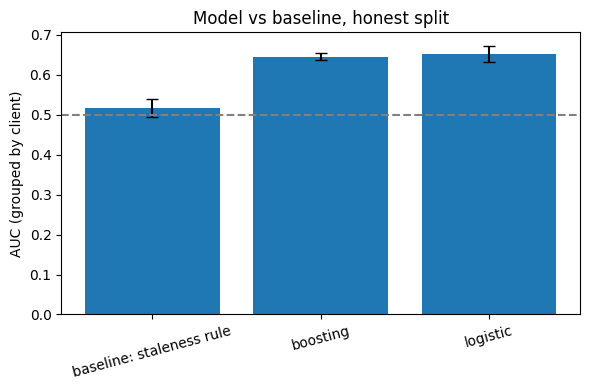

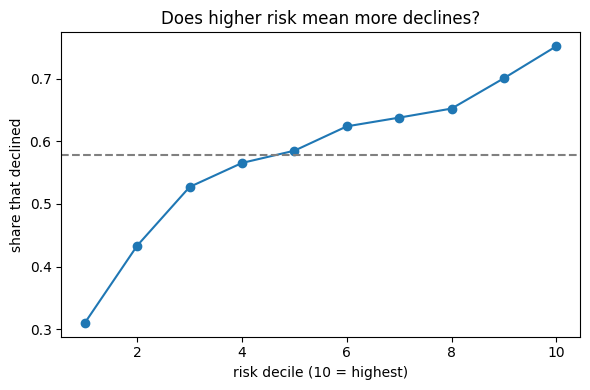

['auc_vs_baseline.png', 'before_after_split.csv', 'decile_decline_rate.png', 'ranked_queue_top500.csv', 'results_table.csv']


In [8]:
import matplotlib.pyplot as plt
os.makedirs("work/outputs", exist_ok=True)

# Tables
table.to_csv("work/outputs/results_table.csv")
queue.drop(columns="declined").head(500).to_csv("work/outputs/ranked_queue_top500.csv", index=False)
cmp_.to_csv("work/outputs/before_after_split.csv")

# Chart 1: model vs baseline on the honest split
auc = honest.groupby("model")["AUC"].agg(["mean", "std"])
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(auc.index, auc["mean"], yerr=auc["std"], capsize=4)
ax.axhline(0.5, ls="--", color="gray"); ax.set_ylabel("AUC (grouped by client)")
ax.set_title("Model vs baseline, honest split"); plt.xticks(rotation=15); plt.tight_layout()
plt.savefig("work/outputs/auc_vs_baseline.png", dpi=150); plt.show()

# Chart 2: decline rate by risk decile (calibration of the ranking)
dec = pd.qcut(q["decline_risk"], 10, labels=False, duplicates="drop")
rate = y.groupby(dec.values).mean()
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(rate.index + 1, rate.values, marker="o"); ax.axhline(y.mean(), ls="--", color="gray")
ax.set_xlabel("risk decile (10 = highest)"); ax.set_ylabel("share that declined")
ax.set_title("Does higher risk mean more declines?"); plt.tight_layout()
plt.savefig("work/outputs/decile_decline_rate.png", dpi=150); plt.show()

print(sorted(os.listdir("work/outputs")))

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
